# 05 · Análisis exploratorio, insights y conclusiones

**Análisis**

Se parte del dataset con las variables derivadas en la etapa 4 (1.006 ofertas, 19 columnas) para responder dónde están las oportunidades laborales para estudiantes y recién egresados: cuánta oferta accesible hay, dónde está y cuánto paga. Se trabaja con medianas y no con promedios, porque la cola de sueldos altos desplaza el promedio.

**Resultado de este análisis:** los puestos que no exigen trayectoria previa (auxiliar, técnico y asistente) son el 17,8 % de las ofertas y pagan una mediana de S/ 2.700, frente a S/ 5.500 del resto. La categoría ocupacional ordena el mercado mejor que la jerarquía: los especialistas y analistas concentran el 54,4 % de las ofertas y la mediana más alta, por encima incluso de las jefaturas. El régimen de contratación marca otra brecha: el D. Leg. 728 paga S/ 6.500 y el CAS S/ 3.800. Lima-Callao paga un 86 % más que el resto del país y la brecha se mantiene en 78 % al excluir a la entidad que domina el dataset. Se generaron 13 figuras en `reports/figures/`, cada una con su interpretación.

## Preparación

In [22]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import mahalanobis

# Rutas: usa src/config.py cuando el notebook corre dentro del repositorio; si no (por ejemplo
# en Colab, con solo el CSV subido), trabaja sobre la carpeta actual.
RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists()), None)

if RAIZ is not None:
    sys.path.insert(0, str(RAIZ))
    from src import config
    from src.graficos import guardar_figura
    ENCODING = config.ENCODING
    DIR_FIGURAS = config.DIR_FIGURAS
    CANDIDATOS = [config.ARCHIVO_FINAL,
                  config.DIR_PROCESSED / "talento_peru_final.csv",
                  config.DIR_INTERIM / "talento_peru_final.csv"]
else:
    ENCODING = "utf-8"
    DIR_FIGURAS = Path("reports/figures")
    CANDIDATOS = [Path("talento_peru_final.csv"), Path("data/processed/talento_peru_final.csv")]

    def guardar_figura(nombre, fig=None, dpi=200):
        DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
        (fig or plt.gcf()).savefig(DIR_FIGURAS / f"{nombre}.png", dpi=dpi, bbox_inches="tight")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
AZUL, VERDE, NARANJA, ROJO = "#4C72B0", "#55A868", "#DD8452", "#C44E52"

In [23]:
ruta = next((r for r in CANDIDATOS if r.exists()), None)
if ruta is None:
    raise FileNotFoundError("Falta talento_peru_final.csv (salida de la etapa 4).")

df = pd.read_csv(ruta, encoding=ENCODING)
print(f"{len(df)} ofertas · {df.shape[1]} columnas · {df['vacantes'].sum()} vacantes")
assert df["id_oferta_hash"].is_unique, "Hay identificadores repetidos"
df.head(3)

1006 ofertas · 19 columnas · 1758 vacantes


,id_oferta_hash,puesto,entidad,numero_convocatoria,vacantes,remuneracion_pen,fecha_inicio_publicacion,fecha_fin_publicacion,departamento,distrito,vacantes_log,rango_salarial,categoria_vacantes,regimen_laboral,modalidad_contrato,puesto_base,categoria_ocupacional,tipo_entidad,macrorregion
0,1af30dbb2f0f39e7d0c908cf,ESPECIALISTA LEGAL,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,5670.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO,0.0,"Medio (4,000-5,999)",1 vacante,D.LEG 1057,NECESIDAD TRANSITORIA,ESPECIALISTA LEGAL,ESPECIALISTA / ANALISTA,JUSTICIA Y MINISTERIO PUBLICO,CENTRO
1,febb4d4b3da59b587a74d154,ASISTENTE LEGAL,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,4000.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO,0.0,"Medio (4,000-5,999)",1 vacante,D.LEG 1057,NECESIDAD TRANSITORIA,ASISTENTE LEGAL,OTROS,JUSTICIA Y MINISTERIO PUBLICO,CENTRO
2,dcde0256d3fc65eed01f4f18,ASISTENTE ADMINISTRATIVO I MODULO,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,3470.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO,0.0,"Medio-bajo (2,500-3,999)",1 vacante,D.LEG 1057,NECESIDAD TRANSITORIA,ASISTENTE ADMINISTRATIVO I MODULO,OTROS,JUSTICIA Y MINISTERIO PUBLICO,CENTRO


In [24]:
# Orden de las categorías, usado en todo el notebook
ORDEN_OCUPACION = [
    "AUXILIAR / OPERATIVO", "TECNICO", "ASISTENTE / APOYO ADMINISTRATIVO",
    "OTROS", "JEFATURA Y COORDINACION", "PROFESIONAL", "ESPECIALISTA / ANALISTA",
]
ORDEN_RANGOS = ["Bajo (< 2,500)", "Medio-bajo (2,500-3,999)", "Medio (4,000-5,999)",
                "Medio-alto (6,000-7,999)", "Alto (>= 8,000)"]
ORDEN_MACRO = ["ORIENTE", "CENTRO", "SUR", "NORTE", "LIMA-CALLAO"]

# Puestos accesibles sin trayectoria previa. Es una agrupación de análisis, no una
# variable nueva: se aplica sobre una vista y el dataset original queda intacto.
OCUPACIONES_ACCESO = ["AUXILIAR / OPERATIVO", "TECNICO", "ASISTENTE / APOYO ADMINISTRATIVO"]
vista = df.assign(acceso=np.where(df["categoria_ocupacional"].isin(OCUPACIONES_ACCESO),
                                  "Puestos de acceso", "Resto del mercado"))
print(f"Columnas del dataset tras crear la vista: {df.shape[1]}")

Columnas del dataset tras crear la vista: 19


## 1. Exploración univariada

Antes de cruzar variables se describe cada una por separado: cómo se reparte el pago, qué tipo de cargos se
ofrecen y en qué territorios y entidades se concentran.

### 1.1 Remuneración mensual

count     1006.0
mean      5150.0
50%       5364.0
min       1127.0
max      21000.0
Rango intercuartílico: S/ 3,103 a S/ 6,500


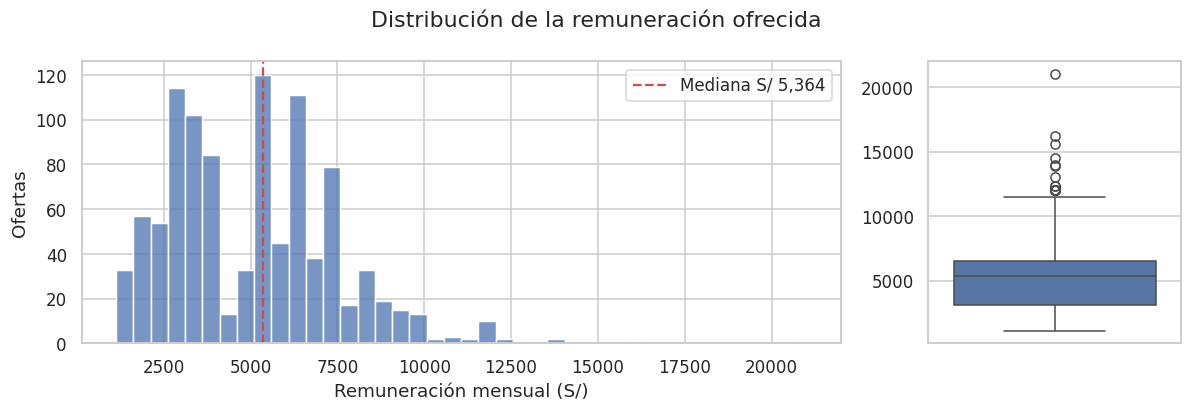

In [25]:
q1, q3 = df["remuneracion_pen"].quantile([0.25, 0.75])
print(df["remuneracion_pen"].describe()[["count", "mean", "50%", "min", "max"]].round(0).to_string())
print(f"Rango intercuartílico: S/ {q1:,.0f} a S/ {q3:,.0f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 1]})
sns.histplot(df["remuneracion_pen"], bins=40, color=AZUL, ax=ax1)
ax1.axvline(df["remuneracion_pen"].median(), color=ROJO, linestyle="--",
            label=f"Mediana S/ {df['remuneracion_pen'].median():,.0f}")
ax1.set_xlabel("Remuneración mensual (S/)")
ax1.set_ylabel("Ofertas")
ax1.legend()
sns.boxplot(y=df["remuneracion_pen"], color=AZUL, ax=ax2)
ax2.set_ylabel("")
fig.suptitle("Distribución de la remuneración ofrecida")
plt.tight_layout()
guardar_figura("05_distribucion_remuneracion")
plt.show()

**Interpretación.** La mediana es S/ 5.364 y la mitad de las ofertas está entre S/ 3.103 y S/ 6.500. La
cola hasta S/ 21.000 empuja el promedio a S/ 5.150, por lo que todo el análisis usa medianas. Los escalones
del histograma son las escalas salariales del Estado (S/ 5.500, 6.500, 7.500).

### 1.2 Qué tipo de cargos se ofrecen

In [26]:
ocupacion = (df.groupby("categoria_ocupacional")
               .agg(ofertas=("id_oferta_hash", "size"),
                    vacantes=("vacantes", "sum"),
                    remuneracion_mediana=("remuneracion_pen", "median"))
               .reindex(ORDEN_OCUPACION))
ocupacion["% de ofertas"] = (ocupacion["ofertas"] / len(df) * 100).round(1)
ocupacion.round(0)

,ofertas,vacantes,remuneracion_mediana,% de ofertas
categoria_ocupacional,,,,
AUXILIAR / OPERATIVO,81,175,2000.0,8.0
TECNICO,58,74,2797.0,6.0
ASISTENTE / APOYO ADMINISTRATIVO,40,49,2973.0,4.0
OTROS,81,100,3100.0,8.0
JEFATURA Y COORDINACION,42,45,3722.0,4.0
PROFESIONAL,157,196,4000.0,16.0
ESPECIALISTA / ANALISTA,547,1119,6500.0,54.0


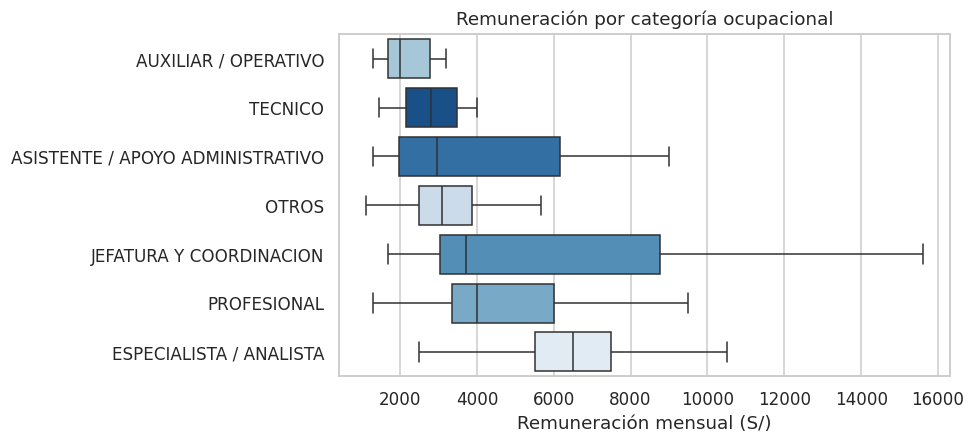

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=df, x="remuneracion_pen", y="categoria_ocupacional", order=ORDEN_OCUPACION,
            hue="categoria_ocupacional", legend=False, palette="Blues", showfliers=False, ax=ax)
ax.set_xlabel("Remuneración mensual (S/)")
ax.set_ylabel("")
ax.set_title("Remuneración por categoría ocupacional")
plt.tight_layout()
guardar_figura("05_remuneracion_por_categoria")
plt.show()

**Interpretación.** El mercado está dominado por una sola categoría: especialistas y analistas son el
54,4 % de las ofertas y la mejor pagada, con S/ 6.500 de mediana. Lo llamativo es que **las jefaturas pagan
menos** (S/ 3.722) pese a estar más arriba en la jerarquía, algo que se explica en la sección 2.2. En el
extremo bajo están los auxiliares (S/ 2.000), los técnicos (S/ 2.797) y los asistentes (S/ 2.973).

### 1.3 Puestos accesibles sin trayectoria previa

Ofertas de acceso: 179 de 1006 (17.8%)
Vacantes correspondientes: 298 de 1758


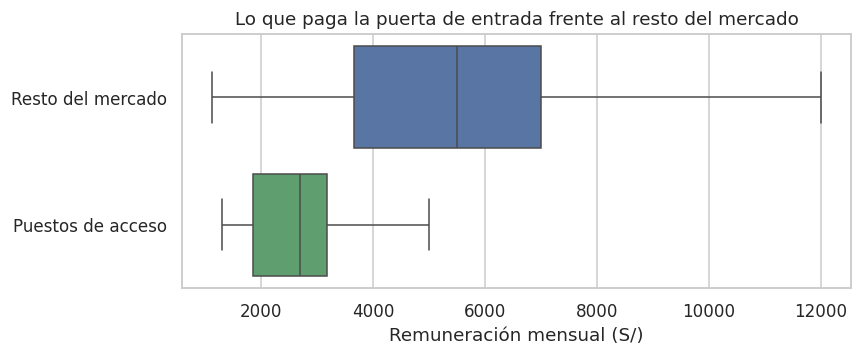

,ofertas,mediana,q1,q3
acceso,,,,
Puestos de acceso,179,2700.0,1864.0,3182.0
Resto del mercado,827,5500.0,3663.0,7000.0


In [7]:
acceso = vista[vista["acceso"] == "Puestos de acceso"]
print(f"Ofertas de acceso: {len(acceso)} de {len(df)} ({len(acceso) / len(df):.1%})")
print(f"Vacantes correspondientes: {acceso['vacantes'].sum()} de {df['vacantes'].sum()}")

fig, ax = plt.subplots(figsize=(8, 3.4))
sns.boxplot(data=vista, x="remuneracion_pen", y="acceso",
            hue="acceso", legend=False, palette={"Puestos de acceso": VERDE, "Resto del mercado": AZUL},
            showfliers=False, ax=ax)
ax.set_xlabel("Remuneración mensual (S/)")
ax.set_ylabel("")
ax.set_title("Lo que paga la puerta de entrada frente al resto del mercado")
plt.tight_layout()
guardar_figura("05_acceso_vs_resto")
plt.show()

vista.groupby("acceso")["remuneracion_pen"].agg(
    ofertas="size", mediana="median", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)
).round(0)

**Interpretación.** Los cargos que no exigen trayectoria —auxiliar, técnico y asistente— son solo el
**17,8 % de las ofertas** (179 de 1.006) y pagan S/ 2.700 de mediana frente a S/ 5.500 del resto: menos de
la mitad. La puerta de entrada existe, pero es estrecha y mal pagada. El resto del análisis busca dónde se
rompe esa regla.

### 1.4 Territorio y entidades

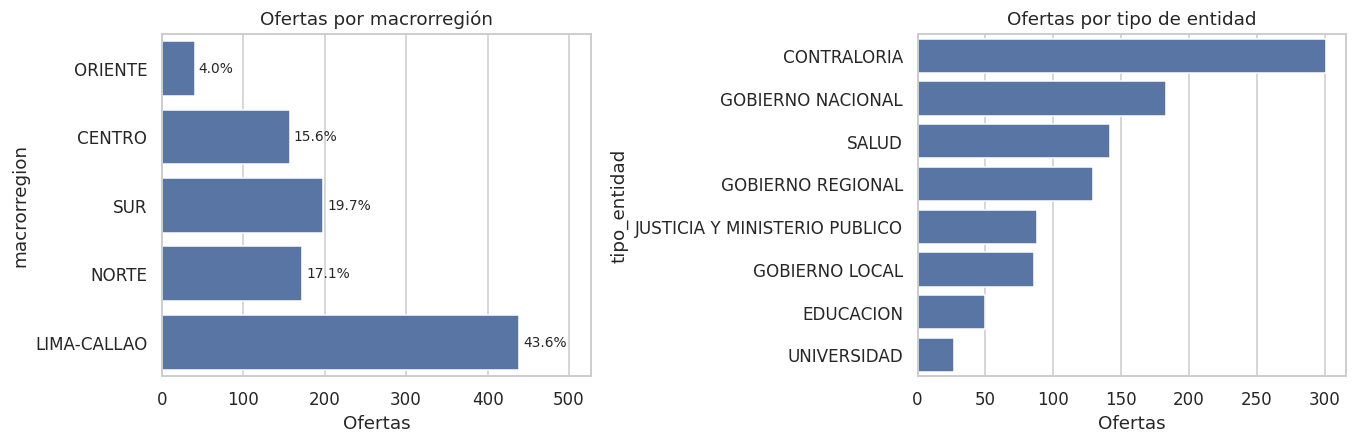

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))

macro = df["macrorregion"].value_counts().reindex(ORDEN_MACRO)
sns.barplot(x=macro.values, y=macro.index, color=AZUL, ax=ax1)
for i, v in enumerate(macro.values):
    ax1.text(v + 5, i, f"{v / len(df):.1%}", va="center", fontsize=9)
ax1.set_xlim(0, macro.max() * 1.2)
ax1.set_xlabel("Ofertas")
ax1.set_title("Ofertas por macrorregión")

tipos = df["tipo_entidad"].value_counts()
sns.barplot(x=tipos.values, y=tipos.index, color=AZUL, ax=ax2)
ax2.set_xlabel("Ofertas")
ax2.set_title("Ofertas por tipo de entidad")

plt.tight_layout()
guardar_figura("05_territorio_y_entidades")
plt.show()

**Interpretación.** Lima-Callao concentra el **43,6 %** de las ofertas, más del doble que cualquier otra
macrorregión; Oriente, con 40, es demasiado pequeña para leer sus porcentajes como representativos. Del lado
de las entidades, la Contraloría publica ella sola 301 ofertas, el 29,9 % del total, siendo **una única
entidad** frente a las 35 del gobierno nacional o las 24 del sector educación. Esa concentración obliga a
comprobar los hallazgos con y sin ella, como se hace en la sección 2.3.

## 2. Relaciones entre variables

La pregunta ahora es dónde conviene buscar: qué entidades, qué regímenes y qué territorios ofrecen mejores
condiciones.

### 2.1 Quién contrata y cuánto paga

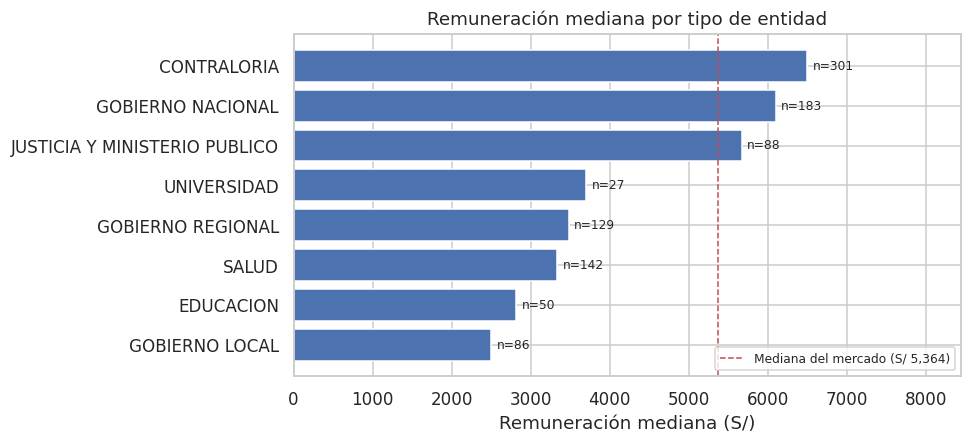

,ofertas,entidades,mediana
tipo_entidad,,,
GOBIERNO LOCAL,86,17,2500.0
EDUCACION,50,24,2816.0
SALUD,142,15,3336.0
GOBIERNO REGIONAL,129,8,3479.0
UNIVERSIDAD,27,6,3700.0
JUSTICIA Y MINISTERIO PUBLICO,88,7,5670.0
GOBIERNO NACIONAL,183,35,6100.0
CONTRALORIA,301,1,6500.0


In [9]:
entidad = (df.groupby("tipo_entidad")
             .agg(ofertas=("id_oferta_hash", "size"),
                  entidades=("entidad", "nunique"),
                  mediana=("remuneracion_pen", "median"))
             .sort_values("mediana"))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(entidad.index, entidad["mediana"], color=AZUL)
for i, (m, n) in enumerate(zip(entidad["mediana"], entidad["ofertas"])):
    ax.text(m + 70, i, f"n={n}", va="center", fontsize=8)
ax.axvline(df["remuneracion_pen"].median(), color=ROJO, linestyle="--", linewidth=1,
           label=f"Mediana del mercado (S/ {df['remuneracion_pen'].median():,.0f})")
ax.set_xlabel("Remuneración mediana (S/)")
ax.set_xlim(0, entidad["mediana"].max() * 1.3)
ax.set_title("Remuneración mediana por tipo de entidad")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
guardar_figura("05_remuneracion_por_tipo_entidad")
plt.show()
entidad.round(0)

**Interpretación.** El tipo de entidad separa el mercado en dos bloques. Abajo, los gobiernos locales
(S/ 2.500), educación (S/ 2.817), salud (S/ 3.336) y los gobiernos regionales (S/ 3.479), todos por debajo
de la mediana del mercado. Arriba, el sistema de justicia (S/ 5.670), el gobierno nacional (S/ 6.100) y la
Contraloría (S/ 6.500). Aquí está la explicación de la anomalía de la sección 1.2: las jefaturas pagan poco
porque se concentran en municipalidades y gobiernos regionales, que son los que menos pagan. Dicho de otro
modo, **importa más dónde se trabaja que qué cargo se ocupa**.

### 2.2 Régimen y modalidad de contratación

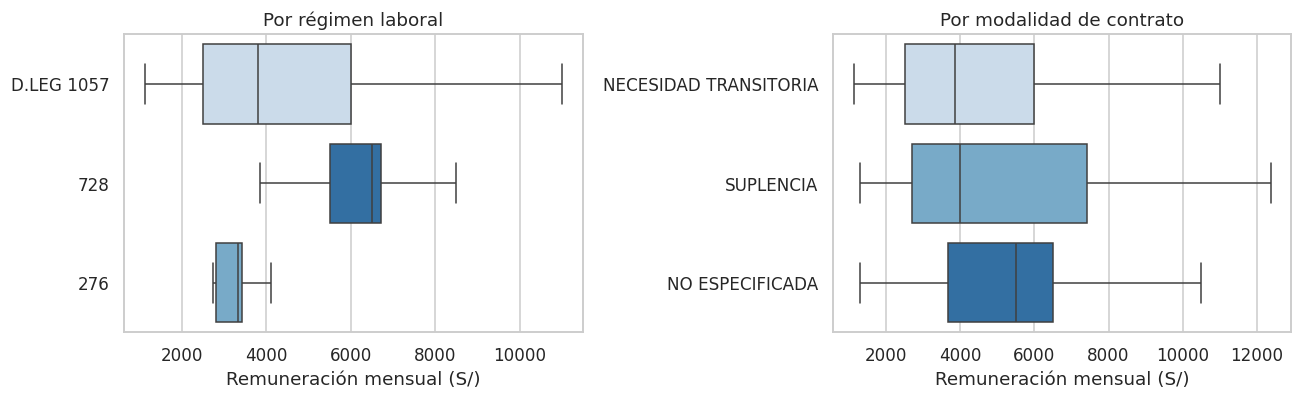

,ofertas,mediana
regimen_laboral,,
D.LEG 1057,531,3800.0
728,389,6500.0
276,81,3318.0
DOCENTES UNIVERSITARIOS LEY 30220,5,5233.0


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))

regimen = (df.groupby("regimen_laboral")
             .agg(ofertas=("id_oferta_hash", "size"), mediana=("remuneracion_pen", "median"))
             .sort_values("ofertas", ascending=False))
sns.boxplot(data=df[df["regimen_laboral"].isin(regimen.index[:3])],
            x="remuneracion_pen", y="regimen_laboral", order=regimen.index[:3],
            hue="regimen_laboral", legend=False, palette="Blues", showfliers=False, ax=ax1)
ax1.set_xlabel("Remuneración mensual (S/)")
ax1.set_ylabel("")
ax1.set_title("Por régimen laboral")

sns.boxplot(data=df, x="remuneracion_pen", y="modalidad_contrato",
            hue="modalidad_contrato", legend=False, palette="Blues", showfliers=False, ax=ax2)
ax2.set_xlabel("Remuneración mensual (S/)")
ax2.set_ylabel("")
ax2.set_title("Por modalidad de contrato")

plt.tight_layout()
guardar_figura("05_regimen_y_modalidad")
plt.show()
regimen.round(0)

**Interpretación.** El régimen de contratación abre una brecha de casi el doble: el D. Leg. 728, el régimen
de la actividad privada, paga **S/ 6.500** de mediana en 389 ofertas, mientras que el CAS (D. Leg. 1057)
paga **S/ 3.800** en 531, y la carrera pública (D. Leg. 276) S/ 3.318 en 81. La modalidad apunta en el mismo
sentido: los contratos por necesidad transitoria pagan S/ 3.864 frente a S/ 5.500 de los que no la
especifican. Para quien postula, el régimen que aparece en el número de convocatoria es un indicador del
sueldo tan fuerte como el nombre del puesto.

### 2.3 El efecto de la concentración: Lima y la Contraloría

In [11]:
sin_contraloria = df[df["tipo_entidad"] != "CONTRALORIA"]

print(f"La Contraloría publica {(df['tipo_entidad'] == 'CONTRALORIA').sum()} ofertas "
      f"({(df['tipo_entidad'] == 'CONTRALORIA').mean():.1%} del total) y "
      f"{(df.loc[df['tipo_entidad'] == 'CONTRALORIA', 'macrorregion'] == 'LIMA-CALLAO').mean():.0%} "
      f"de ellas están en Lima-Callao.\n")

comparacion = pd.DataFrame({
    "Dataset completo": [df[df["macrorregion"] == "LIMA-CALLAO"]["remuneracion_pen"].median(),
                         df[df["macrorregion"] != "LIMA-CALLAO"]["remuneracion_pen"].median()],
    "Sin Contraloría": [sin_contraloria[sin_contraloria["macrorregion"] == "LIMA-CALLAO"]["remuneracion_pen"].median(),
                        sin_contraloria[sin_contraloria["macrorregion"] != "LIMA-CALLAO"]["remuneracion_pen"].median()],
}, index=["Lima-Callao", "Resto del país"])
comparacion.loc["Lima paga más (%)"] = (
    (comparacion.loc["Lima-Callao"] / comparacion.loc["Resto del país"] - 1) * 100
).round(1)
comparacion.round(0)

La Contraloría publica 301 ofertas (29.9% del total) y 63% de ellas están en Lima-Callao.



,Dataset completo,Sin Contraloría
Lima-Callao,6500.0,6000.0
Resto del país,3500.0,3374.0
Lima paga más (%),86.0,78.0


**Interpretación.** La Contraloría publica el 29,9 % de las ofertas y el 63 % de ellas están en Lima, así
que podría estar inventando la brecha territorial. Al repetir el cálculo sin esa entidad, la brecha baja de
86 % a 78 % pero no desaparece: el centralismo salarial no es artefacto de una entidad dominante.

### 2.4 Composición salarial de cada macrorregión

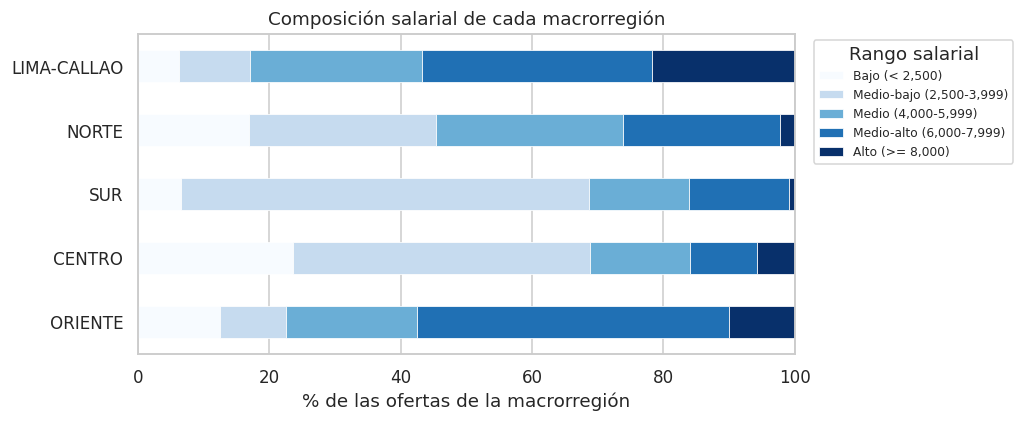

rango_salarial,"Bajo (< 2,500)","Medio-bajo (2,500-3,999)","Medio (4,000-5,999)","Medio-alto (6,000-7,999)","Alto (>= 8,000)"
macrorregion,,,,,
ORIENTE,12.5,10.0,20.0,47.5,10.0
CENTRO,23.6,45.2,15.3,10.2,5.7
SUR,6.6,62.1,15.2,15.2,1.0
NORTE,16.9,28.5,28.5,23.8,2.3
LIMA-CALLAO,6.2,10.9,26.2,34.9,21.9


In [12]:
composicion = (df.groupby(["macrorregion", "rango_salarial"], observed=True).size()
                 .unstack()
                 .reindex(index=ORDEN_MACRO, columns=ORDEN_RANGOS))
composicion_pct = (composicion.div(composicion.sum(axis=1), axis=0) * 100).round(1)

ax = composicion_pct.plot.barh(stacked=True, figsize=(9.5, 4), colormap="Blues",
                               edgecolor="white", linewidth=0.5)
ax.set_xlabel("% de las ofertas de la macrorregión")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Composición salarial de cada macrorregión")
ax.legend(title="Rango salarial", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
guardar_figura("05_composicion_salarial_macrorregion")
plt.show()
composicion_pct

**Interpretación.** La diferencia entre territorios no es solo de nivel, sino de **composición**: en
Lima-Callao los tramos medio-alto y alto suman el 56,8 % de las ofertas, mientras que en el Sur el 62,1 %
cae en el tramo medio-bajo y en el Centro el 68,8 % está en los dos tramos más bajos. Fuera de Lima casi no
se publican convocatorias en los tramos altos.

## 3. Segmentación de las ofertas

Hasta aquí se compararon variables de a dos. La segmentación busca si las ofertas forman **perfiles**
reconocibles al mirar varias características a la vez. Se usa K-means sobre la remuneración y el volumen de
vacantes, normalizados con min-max, más la categoría ocupacional codificada en binario y dividida entre el
número de categorías, como en el laboratorio de clustering, para que el bloque categórico no domine.

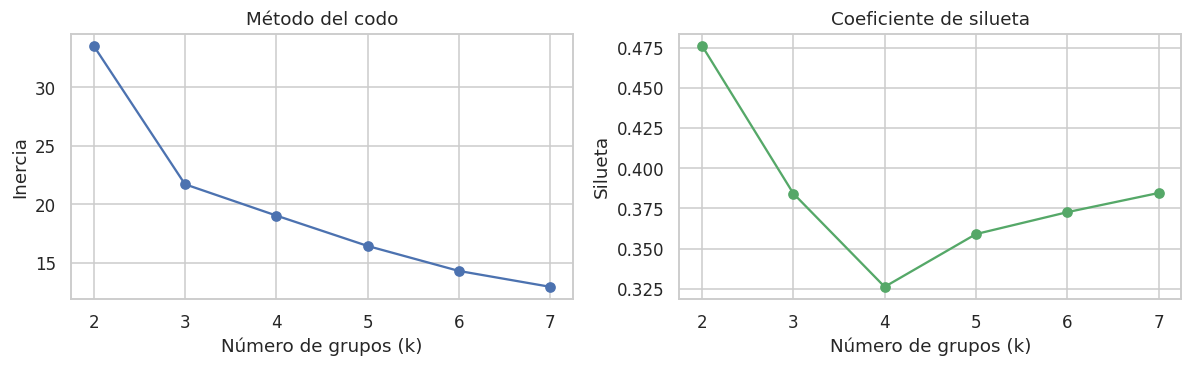

In [13]:
VARIABLES = ["remuneracion_pen", "vacantes_log"]
X = df[VARIABLES].copy()
X = (X - X.min()) / (X.max() - X.min())
dummies = pd.get_dummies(df["categoria_ocupacional"], dtype=int)
X = X.join(dummies / dummies.shape[1])

inercia, siluetas, ks = [], [], range(2, 8)
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inercia.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(list(ks), inercia, marker="o", color=AZUL)
ax1.set_xlabel("Número de grupos (k)")
ax1.set_ylabel("Inercia")
ax1.set_title("Método del codo")
ax2.plot(list(ks), siluetas, marker="o", color=VERDE)
ax2.set_xlabel("Número de grupos (k)")
ax2.set_ylabel("Silueta")
ax2.set_title("Coeficiente de silueta")
plt.tight_layout()
guardar_figura("05_kmeans_seleccion_k")
plt.show()

**Interpretación.** El codo se produce entre k = 3 y k = 4: la inercia cae de 33,5 a 21,7 y luego a 19,0,
y a partir de ahí baja despacio. La silueta es moderada (0,33 con k = 4) porque las variables binarias
añaden dimensiones y separan menos que las numéricas puras. Se elige **k = 4**, que es donde los grupos
resultan interpretables.

In [14]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X)
vista["segmento"] = kmeans.labels_

perfil = (vista.groupby("segmento")
               .agg(ofertas=("id_oferta_hash", "size"),
                    remuneracion=("remuneracion_pen", "median"),
                    vacantes=("vacantes", "median")))
perfil.round(0)

,ofertas,remuneracion,vacantes
segmento,,,
0,136,8950.0,1.0
1,372,6432.0,1.0
2,107,5500.0,5.0
3,391,3000.0,1.0


In [15]:
for s in range(K):
    sub = vista[vista["segmento"] == s]
    print(f"Segmento {s} · {len(sub)} ofertas · mediana S/ {sub['remuneracion_pen'].median():,.0f}")
    print(f"   cargos   : {dict(sub['categoria_ocupacional'].value_counts().head(2))}")
    print(f"   entidades: {dict(sub['tipo_entidad'].value_counts().head(2))}")

Segmento 0 · 136 ofertas · mediana S/ 8,950
   cargos   : {'ESPECIALISTA / ANALISTA': np.int64(81), 'PROFESIONAL': np.int64(35)}
   entidades: {'GOBIERNO NACIONAL': np.int64(73), 'SALUD': np.int64(31)}
Segmento 1 · 372 ofertas · mediana S/ 6,432
   cargos   : {'ESPECIALISTA / ANALISTA': np.int64(359), 'ASISTENTE / APOYO ADMINISTRATIVO': np.int64(9)}
   entidades: {'CONTRALORIA': np.int64(200), 'GOBIERNO NACIONAL': np.int64(53)}
Segmento 2 · 107 ofertas · mediana S/ 5,500
   cargos   : {'ESPECIALISTA / ANALISTA': np.int64(72), 'AUXILIAR / OPERATIVO': np.int64(18)}
   entidades: {'CONTRALORIA': np.int64(64), 'GOBIERNO LOCAL': np.int64(15)}
Segmento 3 · 391 ofertas · mediana S/ 3,000
   cargos   : {'PROFESIONAL': np.int64(114), 'OTROS': np.int64(72)}
   entidades: {'SALUD': np.int64(97), 'GOBIERNO REGIONAL': np.int64(76)}


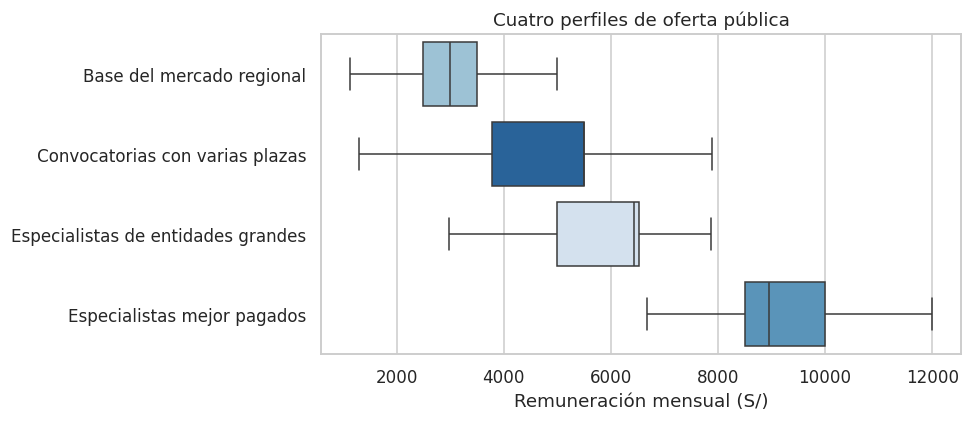

In [16]:
NOMBRES = {
    0: "Especialistas mejor pagados",
    1: "Especialistas de entidades grandes",
    2: "Convocatorias con varias plazas",
    3: "Base del mercado regional",
}
vista["nombre_segmento"] = vista["segmento"].map(NOMBRES)

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=vista, x="remuneracion_pen", y="nombre_segmento",
            order=[NOMBRES[i] for i in perfil["remuneracion"].sort_values().index],
            hue="nombre_segmento", legend=False, palette="Blues", showfliers=False, ax=ax)
ax.set_xlabel("Remuneración mensual (S/)")
ax.set_ylabel("")
ax.set_title("Cuatro perfiles de oferta pública")
plt.tight_layout()
guardar_figura("05_segmentos_kmeans")
plt.show()

**Interpretación.** Los cuatro grupos ordenan el mercado por remuneración y volumen de plazas.

| Segmento | Ofertas | Mediana | Qué es |
|---|---|---|---|
| Base del mercado regional | 391 | S/ 3.000 | Profesionales y auxiliares en salud y gobiernos regionales |
| Convocatorias con varias plazas | 107 | S/ 5.500 | Procesos de 5 plazas en promedio, sobre todo de la Contraloría |
| Especialistas de entidades grandes | 372 | S/ 6.432 | Especialistas y analistas de la Contraloría y el gobierno nacional |
| Especialistas mejor pagados | 136 | S/ 8.950 | Especialistas, profesionales y jefaturas del gobierno nacional |

El grupo más numeroso es también el peor pagado, y es el que concentra la oferta de regiones. Para quien
busca trabajo, el segmento de convocatorias con varias plazas es el más interesante: paga por encima de la
mediana del mercado y, al ofrecer varias vacantes, la probabilidad de entrar es mayor.

### 3.1 Perfil de los centroides

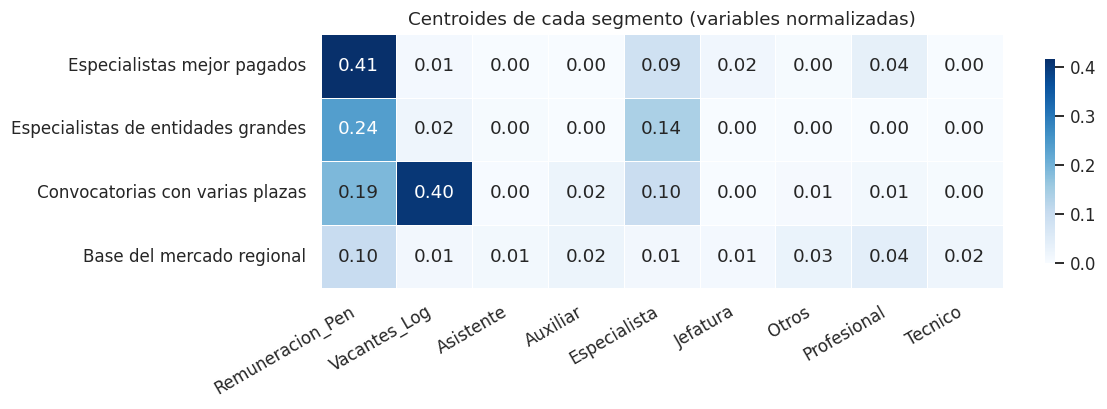

In [17]:
centroides = pd.DataFrame(
    [X[vista["segmento"] == s].mean() for s in range(K)],
    index=[NOMBRES[s] for s in range(K)],
)
# Nombres cortos para que las etiquetas quepan en el gráfico
centroides.columns = [c.split(" /")[0].split(" Y ")[0].title() for c in centroides.columns]

plt.figure(figsize=(10, 3))
sns.heatmap(centroides, annot=True, fmt=".2f", cmap="Blues", linewidths=.5,
            cbar_kws={"shrink": 0.8})
plt.xticks(rotation=30, ha="right")
plt.title("Centroides de cada segmento (variables normalizadas)")
guardar_figura("05_centroides_segmentos")
plt.show()

**Interpretación.** El mapa de calor muestra qué separa a cada grupo. `remuneracion_pen` es el eje
principal y ordena los cuatro segmentos. `vacantes_log` solo se activa en uno de ellos, el de convocatorias
con varias plazas, que es lo que lo distingue del resto. Entre las categorías ocupacionales, la de
especialista y analista es la que más pesa en los dos segmentos mejor pagados.

## 4. Anomalías

Se buscan las ofertas que se apartan del patrón en los tres niveles vistos en el laboratorio de outliers:
**univariado** (rango intercuartílico), **bivariado** (dos variables a la vez) y **multivariado**
(distancia de Mahalanobis). No se eliminan: la limpieza de la etapa 2 ya retiró los valores imposibles, de
modo que lo que queda son ofertas reales y lo que interesa es **qué las explica**.

### 4.1 Outliers univariados: remuneración

Límite superior: S/ 11,595 · ofertas por encima: 19 (1.9%)


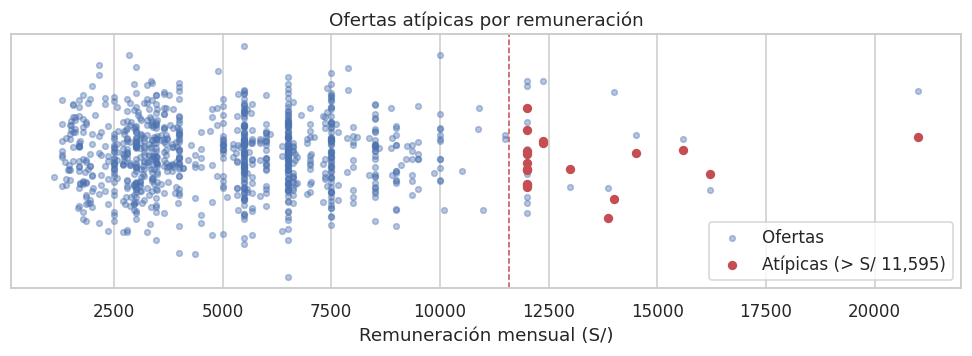

tipo_entidad
GOBIERNO NACIONAL                13
JUSTICIA Y MINISTERIO PUBLICO     6


,puesto,entidad,remuneracion_pen
247,ASESOR DE MAGISTRADO,TRIBUNAL CONSTITUCIONAL,21000.0
246,ASESOR JURISDICCIONAL II,TRIBUNAL CONSTITUCIONAL,16200.0
343,COORDINADOR/A DE POLÍTICAS EN PLANEAMIENTO Y E...,MINISTERIO DE ENERGIA Y MINAS,15600.0
26,EJECUTIVO/A EN PRESUPUESTO POR RESULTADOS - EJ...,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIEN...,14500.0
592,EXPERTO LEGAL EN GESTIÓN PÚBLICA,AUTORIDAD NACIONAL DE INFRAESTRUCTURA,14000.0


In [18]:
limite = q3 + 1.5 * (q3 - q1)
atipicas = df[df["remuneracion_pen"] > limite]
print(f"Límite superior: S/ {limite:,.0f} · ofertas por encima: {len(atipicas)} ({len(atipicas) / len(df):.1%})")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.scatter(df["remuneracion_pen"], np.random.default_rng(42).normal(0, 0.06, len(df)),
           s=14, color=AZUL, alpha=0.4, label="Ofertas")
ax.scatter(atipicas["remuneracion_pen"], np.random.default_rng(7).normal(0, 0.06, len(atipicas)),
           s=26, color=ROJO, label=f"Atípicas (> S/ {limite:,.0f})")
ax.axvline(limite, color=ROJO, linestyle="--", linewidth=1)
ax.set_yticks([])
ax.set_xlabel("Remuneración mensual (S/)")
ax.set_title("Ofertas atípicas por remuneración")
ax.legend()
plt.tight_layout()
guardar_figura("05_anomalias_remuneracion")
plt.show()

print(atipicas["tipo_entidad"].value_counts().to_string())
atipicas[["puesto", "entidad", "remuneracion_pen"]].nlargest(5, "remuneracion_pen")

**Interpretación.** Solo 19 ofertas (1,9 %) superan los S/ 11.595, y no son errores: son cargos de asesoría
y jefatura del gobierno nacional (13) y del sistema de justicia (6), encabezados por un asesor de magistrado
del Tribunal Constitucional con S/ 21.000. Ningún gobierno local, universidad ni establecimiento de salud
aparece: el techo salarial está en el gobierno nacional y la justicia.

### 4.2 Outliers bivariados: remuneración y vacantes

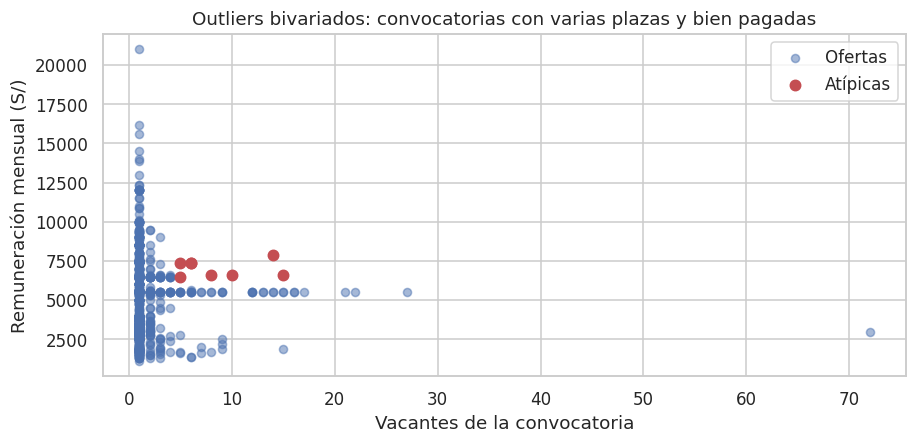

Ofertas atípicas en el plano remuneración-vacantes: 8


,puesto,entidad,vacantes,remuneracion_pen
231,ESPECIALISTA JUDICIAL DE AUDIENCIA,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,15,6620.00
227,ESPECIALISTA JUDICIAL DE SALA,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,14,7880.00
229,ESPECIALISTA JUDICIAL DE JUZGADO,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,10,6620.00
234,ASISTENTE JURISDICCIONAL,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,8,6620.00
564,DEFENSOR PÚBLICO EN EL NUEVO CÓDIGO PROCESAL P...,MINISTERIO DE JUSTICIA Y DERECHOS HUMANOS,6,7364.19
566,DEFENSOR PÚBLICO DE ASISTENCIA LEGAL SNEJ,MINISTERIO DE JUSTICIA Y DERECHOS HUMANOS,6,7364.19
565,DEFENSOR PÚBLICO DE DEFENSA DE VÍCTIMAS SNEJ,MINISTERIO DE JUSTICIA Y DERECHOS HUMANOS,5,7364.19
780,PERFIL 791-2026 ANALISTA II LEGAL EN EVALUACIÓ...,CONTRALORIA GENERAL DE LA REPUBLICA,5,6500.00


In [19]:
# Boolean mask construida a partir del gráfico, como en el laboratorio de outliers
BM = (df["remuneracion_pen"] > 6000) & (df["vacantes"] >= 5)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.scatter(df.loc[~BM, "vacantes"], df.loc[~BM, "remuneracion_pen"],
           s=28, color=AZUL, alpha=0.5, label="Ofertas")
ax.scatter(df.loc[BM, "vacantes"], df.loc[BM, "remuneracion_pen"],
           s=46, color=ROJO, label="Atípicas")
ax.set_xlabel("Vacantes de la convocatoria")
ax.set_ylabel("Remuneración mensual (S/)")
ax.set_title("Outliers bivariados: convocatorias con varias plazas y bien pagadas")
ax.legend()
plt.tight_layout()
guardar_figura("05_anomalias_bivariadas")
plt.show()

print(f"Ofertas atípicas en el plano remuneración-vacantes: {int(BM.sum())}")
df.loc[BM, ["puesto", "entidad", "vacantes", "remuneracion_pen"]].sort_values("vacantes", ascending=False)

**Interpretación.** La nube tiene forma de L: la mediana casi no cambia con el número de vacantes, pero
**el techo sí cae**. Entre las convocatorias de una sola plaza hay sueldos de hasta S/ 21.000, mientras que
las de 10 o más vacantes no pasan de S/ 7.880: los puestos mejor pagados son siempre únicos. Las ofertas
marcadas en rojo rompen ese patrón al combinar cinco o más plazas con más de S/ 6.000, y casi todas vienen
del sistema de justicia. Son las más valiosas para quien postula: pagan por encima de la mediana y tienen
varias plazas.

### 4.3 Outliers multivariados: distancia de Mahalanobis

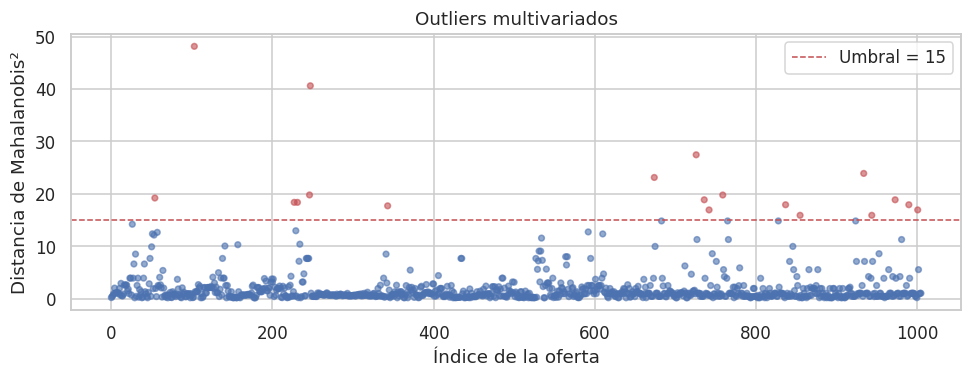

Ofertas con distancia mayor al umbral: 19 (1.9%)


,puesto,entidad,vacantes,remuneracion_pen,distancia
103,ESPECIALISTA JUDICIAL DE JUZGADO,PODER JUDICIAL,72,2972.0,48.2
247,ASESOR DE MAGISTRADO,TRIBUNAL CONSTITUCIONAL,1,21000.0,40.6
726,PERFIL 665-2026 AUDITOR/A ANALISTA I EN SISTEM...,CONTRALORIA GENERAL DE LA REPUBLICA,27,5500.0,27.5
934,PERFIL 592-2026 AUDITOR/A ANALISTA I EN SISTEM...,CONTRALORIA GENERAL DE LA REPUBLICA,22,5500.0,23.9
674,PERFIL 518-2026 AUDITOR/A ANALISTA I EN SISTEM...,CONTRALORIA GENERAL DE LA REPUBLICA,21,5500.0,23.1
246,ASESOR JURISDICCIONAL II,TRIBUNAL CONSTITUCIONAL,1,16200.0,19.8
759,PERFIL 632-2026 AUDITOR/A ANALISTA I EN SISTEM...,CONTRALORIA GENERAL DE LA REPUBLICA,17,5500.0,19.8
54,SERENO A PIE,MUNICIPALIDAD DISTRITAL DE PUEBLO LIBRE,15,1900.0,19.2


In [20]:
DIMENSIONES = ["remuneracion_pen", "vacantes_log"]
Xm = df[DIMENSIONES]
Xm = (Xm - Xm.min()) / (Xm.max() - Xm.min())   # normalización min-max

IC = np.linalg.pinv(Xm.cov().values)
media = Xm.mean().values
distancias = pd.Series([mahalanobis(Xm.iloc[i, :], media, IC) ** 2 for i in range(len(Xm))],
                       index=df.index)

UMBRAL = 15
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(df.index, distancias, s=14,
           c=np.where(distancias > UMBRAL, ROJO, AZUL), alpha=0.6)
ax.axhline(UMBRAL, color=ROJO, linestyle="--", linewidth=1, label=f"Umbral = {UMBRAL}")
ax.set_xlabel("Índice de la oferta")
ax.set_ylabel("Distancia de Mahalanobis²")
ax.set_title("Outliers multivariados")
ax.legend()
plt.tight_layout()
guardar_figura("05_anomalias_mahalanobis")
plt.show()

extremas = df.loc[distancias > UMBRAL]
print(f"Ofertas con distancia mayor al umbral: {len(extremas)} ({len(extremas) / len(df):.1%})")
extremas.assign(distancia=distancias[distancias > UMBRAL].round(1)) \
        [["puesto", "entidad", "vacantes", "remuneracion_pen", "distancia"]] \
        .nlargest(8, "distancia")

**Interpretación.** La distancia de Mahalanobis mira las dos variables a la vez y su correlación, así que
detecta ofertas raras *en conjunto* aunque ningún valor lo sea por separado: aparecen convocatorias que
combinan muchas plazas con sueldos altos o muy bajos, casos que el rango intercuartílico no marca. No se
eliminan, pero conviene tenerlas presentes porque son las que más pueden mover un promedio.

## 5. Insights y recomendaciones

Cada insight indica el hallazgo, la evidencia que lo respalda y qué puede hacer con él un estudiante o
recién egresado.

**Insight 1 · La puerta de entrada es estrecha y paga menos de la mitad.**
*Evidencia:* los cargos de auxiliar, técnico y asistente son 179 de 1.006 ofertas (17,8 %), con una mediana
de S/ 2.700 frente a S/ 5.500 del resto (sección 1.3).
*Recomendación:* no competir solo por los puestos que llevan "asistente" o "técnico" en el título. Conviene
revisar las convocatorias de especialista o analista de primer nivel, que son el 54,4 % del mercado y pagan
S/ 6.500.

**Insight 2 · Importa más dónde se trabaja que qué cargo se ocupa.**
*Evidencia:* las jefaturas pagan S/ 3.722, menos que los especialistas (S/ 6.500), porque se concentran en
gobiernos locales y regionales, cuyas medianas son S/ 2.500 y S/ 3.479 frente a S/ 6.500 de la Contraloría
(secciones 1.2 y 2.1).
*Recomendación:* elegir la entidad antes que el cargo. Un puesto intermedio en el gobierno nacional o en la
Contraloría paga más que una jefatura municipal.

**Insight 3 · El régimen de contratación anticipa el sueldo.**
*Evidencia:* el D. Leg. 728 paga S/ 6.500 de mediana y el CAS S/ 3.800; los contratos por necesidad
transitoria pagan S/ 3.864 frente a S/ 5.500 de los que no la especifican (sección 2.2).
*Recomendación:* leer el número de convocatoria antes de postular: el régimen que aparece ahí predice la
remuneración tan bien como el nombre del puesto.

**Insight 4 · Las convocatorias con varias plazas son la mejor relación entre acceso y sueldo.**
*Evidencia:* el segmento de K-means con cinco plazas de mediana paga S/ 5.500, por encima de la mediana del
mercado, y las 8 ofertas atípicas del plano remuneración-vacantes combinan cinco o más plazas con más de
S/ 6.000 (secciones 3 y 4.2).
*Recomendación:* priorizar esas convocatorias, porque a igual sueldo la probabilidad de entrar es varias
veces mayor que en un proceso de una sola vacante.

**Insight 5 · El centralismo salarial es real y no lo explica una sola entidad.**
*Evidencia:* Lima-Callao concentra el 43,6 % de las ofertas y paga S/ 6.500 frente a S/ 3.500 del resto
(86 % más); al excluir a la Contraloría la brecha sigue en 78 %. En el Sur, el 62,1 % de las ofertas cae en
el tramo medio-bajo (secciones 2.3 y 2.4).
*Recomendación:* comparar ofertas dentro de cada territorio y no en montos absolutos. Para quien no puede
mudarse, el mejor objetivo son las sedes regionales de entidades nacionales, que llevan la escala de pago de
Lima al interior.

## 6. Conclusiones

1. **Sobre el objetivo general.** El dataset permite caracterizar la oferta pública vigente en el corte de
   septiembre de 2026 y aislar el segmento accesible a quien no tiene trayectoria: 179 ofertas, el 17,8 %
   del total, con una mediana de S/ 2.700. La conclusión práctica es que la puerta de entrada del Estado es
   más estrecha de lo que sugiere el volumen total de convocatorias.

2. **Sobre qué determina el pago.** El factor con más efecto no es la jerarquía del cargo sino la entidad
   que convoca y el régimen bajo el que contrata: las jefaturas pagan menos que los especialistas porque se
   concentran en gobiernos locales, y el D. Leg. 728 paga casi el doble que el CAS. Las variables
   construidas en la etapa 4 —`categoria_ocupacional`, `tipo_entidad` y `regimen_laboral`— son las que
   hicieron visible ese patrón, imposible de ver en los campos originales del portal.

3. **Sobre el territorio.** El centralismo se confirma en volumen (43,6 % de las ofertas en Lima-Callao) y
   en remuneración (Lima paga 86 % más que el resto del país), y se mantiene al excluir la entidad que
   domina el dataset, donde la brecha sigue siendo del 78 %. No es, por tanto, un artefacto de la
   composición de la muestra.

4. **Limitaciones.** El análisis describe un corte de dos días y no una serie temporal, por lo que no
   permite afirmar nada sobre tendencias. La categoría ocupacional se infiere de la denominación del cargo,
   ya que el portal no publica experiencia ni formación exigidas, y deja 81 ofertas sin clasificar. Una sola
   entidad concentra el 29,9 % de las ofertas, lo que obliga a verificar cada hallazgo con y sin ella, como
   se hizo en la sección 2.3. Por último, la fuente cubre solo el empleo público, así que las conclusiones
   no se extienden al mercado laboral peruano en su conjunto.

5. **Trabajo futuro.** Repetir la extracción de forma periódica convertiría la fotografía en una serie y
   permitiría estudiar estacionalidad y duración real de las convocatorias; incorporar las bases de cada
   convocatoria añadiría la experiencia y la formación exigidas, que es el dato que hoy debe estimarse a
   partir del título del puesto.

## 7. Figuras guardadas para el informe

In [21]:
figuras = sorted(p.name for p in DIR_FIGURAS.glob("05_*.png"))
print(f"{len(figuras)} figuras en reports/figures/:")
for f in figuras:
    print("  -", f)

13 figuras en reports/figures/:
  - 05_acceso_vs_resto.png
  - 05_anomalias_bivariadas.png
  - 05_anomalias_mahalanobis.png
  - 05_anomalias_remuneracion.png
  - 05_centroides_segmentos.png
  - 05_composicion_salarial_macrorregion.png
  - 05_distribucion_remuneracion.png
  - 05_kmeans_seleccion_k.png
  - 05_regimen_y_modalidad.png
  - 05_remuneracion_por_categoria.png
  - 05_remuneracion_por_tipo_entidad.png
  - 05_segmentos_kmeans.png
  - 05_territorio_y_entidades.png
